torch version: 2.9.0+cpu
c:\Miniconda\python.exe
The average refractive index is:  1.9


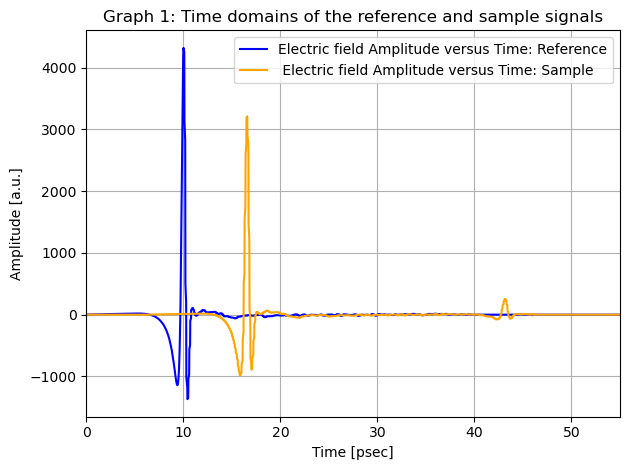

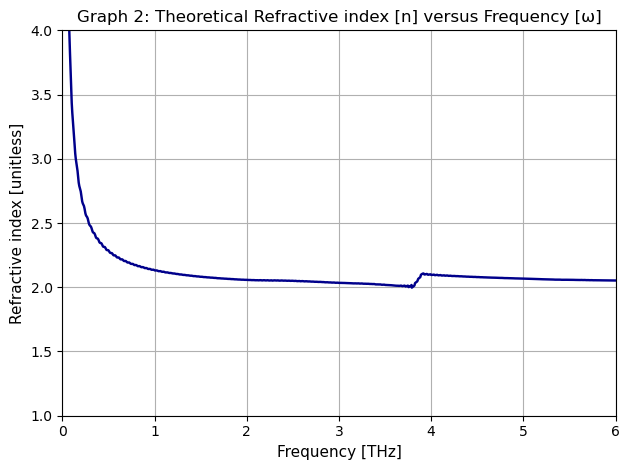

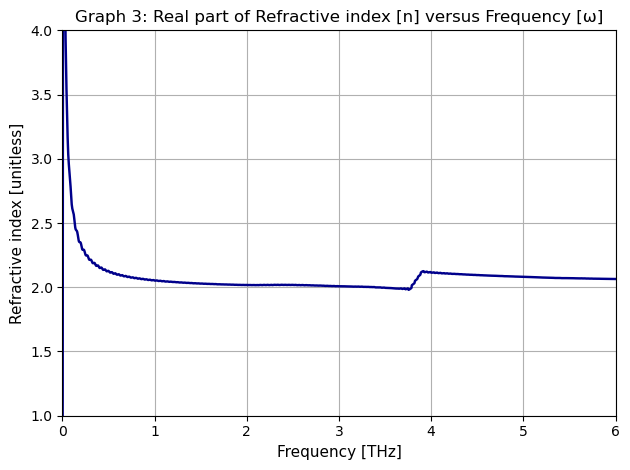

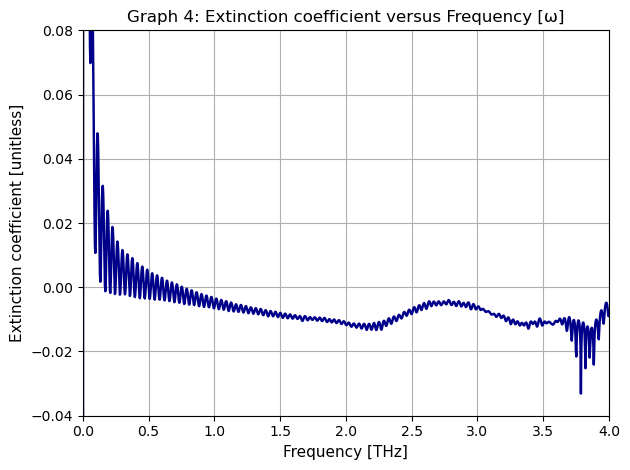

In [19]:
import numpy as np 
import matplotlib.pyplot as plt

import sys 
import torch


# INSERT DATA 
data1 = np.loadtxt("AmpTimeRef.txt",dtype=float)
data2 = np.loadtxt("AmpTimeSample.txt",dtype=float)

print('torch version:', torch.__version__)
print(sys.executable)
t1= data1[:,0] 
y1 = data1[:,1]
t2 = data2[:,0] 
y2 = data2[:,1]

# INTERPOLATION
startt = 0
endt = 46.1 * 1e-11
dt = min(np.mean(np.diff(t2)), np.mean(np.diff(t1)))
t = np.arange(startt, endt + dt, dt)

sr = np.interp(t, t1, y1, left=0, right=0)
ss = np.interp(t, t2, y2, left=0, right=0)

# FFTS
fftr = np.fft.fft(sr, 16384)
ffts = np.fft.fft(ss, 16384)
freq = np.fft.fftfreq(16384, dt) #time to frequency


# MASKING THE NEGATIVE FREQUENCIES
mask = (freq >= 0) 
fftr = fftr[mask]
ffts = ffts[mask]
freq = freq[mask]

freq[freq == 0] = 1e-12  # Replace zeros with a small value to avoid division by zero

# TRANSFER FUNCTION
tamp = (ffts / fftr)
ln_exp = np.log(np.abs(tamp))
tphase = np.angle(tamp)

# PHASE
tphase_unwrapped = np.unwrap(tphase)
tphase_unwrapped -= tphase_unwrapped[0]-0.2

uwr = np.unwrap(np.angle(fftr))
uws= np.unwrap(np.angle(ffts))
delta = uws - uwr

# REFRACTIVE INDEX THEORETICAL
dt =  6* 1e-12 #seconds
c = 3e8 #speed of light in m/s
d = 2e-3 #thickness of sample in m
n_0 = 1  # Refractive index of air

navg = 1 + (c * dt) / d
print("The average refractive index is: ", navg)

n = 1 + (np.abs(delta)* c) / (2 * np.pi * freq  * d)

#NEWTON RAPHSON METHOD
def G_zero(n, f, ln_exp):

    ln_th =(np.log((4 * n_0 * n) / (n_0 + n)**2)
             -(1j * 2 * np.pi * f * d / c) * (n - n_0))
    return  ln_th - ln_exp

def G_zerod(n, f):
    p = 1 / n
    m = 2 / (n + n_0) + (1j * 2 * np.pi* f * d) / c 
    return p - m 

def new_raph(n_1, ln_exp, f, iterations, tol):
    n = n_1
    for i in range(iterations): 
        G_zero_ = G_zero(n,  f, ln_exp)
        G_zerod_ = G_zerod(n, f)
        dn = G_zero_ / G_zerod_
        n = n - dn
        if abs(G_zero_/G_zerod_) < tol:
           # print(i, "iterations")
            break
    return n


# INITIAL GUESS AND CALCULATION
n_1 = 1.8 + 0.05j
n_ = []

for i, f in enumerate(freq, 0):
    ln_exp = np.log(np.abs(tamp[i])) + 1j * tphase_unwrapped[i]
    n_values = new_raph( n_1 ,ln_exp, f,  iterations=50, tol=1e-10)
    n_.append(n_values)


# print("Refractive index values:", n_)
n_ = np.array(n_)




# PLOTTING

# AMPLITUDE VERSUS TIME
plt.xlabel("Time [psec]")
plt.ylabel("Amplitude [a.u.]")
plt.title("Graph 1: Time domains of the reference and sample signals", fontsize = 12)
plt.plot(t *1e12  ,sr, linewidth = 1.5, color = "blue")
plt.plot(t *1e12, ss,  linewidth = 1.5, color = "orange")
plt.legend(["Electric field Amplitude versus Time: Reference", " Electric field Amplitude versus Time: Sample"])
plt.xlim(0,55)
plt.grid()
plt.tight_layout()
plt.show()

# THEORETICAL REFRACTIVE INDEX
plt.plot( freq * 1e-12, n , color = "darkblue", linewidth = 1.75)
plt.title("Graph 2: Theoretical Refractive index [n] versus Frequency [ω]", fontsize = 12)         
plt.xlabel("Frequency [THz]", fontsize = 11)
plt.ylabel("Refractive index [unitless]", fontsize = 11)   
plt.xlim(xmax = 6, xmin = 0 )
plt.ylim(ymax = 4, ymin = 1)
plt.grid()
plt.tight_layout()
plt.show()


# REFRACTIVE INDEX REAL PART
plt.title("Graph 3: Real part of Refractive index [n] versus Frequency [ω]", fontsize = 12)
plt.plot ( freq *1e-12 , np.real(n_), linewidth=1.75, color='darkblue')
plt.ylabel("Refractive index [unitless]", fontsize = 11)
plt.xlabel("Frequency [THz]", fontsize = 11)
plt.xlim(xmax = 6, xmin = 0)
plt.ylim(ymax = 4, ymin = 1)
plt.grid()
plt.tight_layout()
plt.show()

# REFRACTIVE INDEX IMAGINARY PART
plt.title("Graph 4: Extinction coefficient versus Frequency [ω]", fontsize = 12)
plt.plot ( freq *1e-12 , np.imag(n_), linewidth=1.75, color='darkblue')
plt.ylabel("Extinction coefficient [unitless]", fontsize = 11)
plt.xlabel("Frequency [THz]", fontsize = 11)
plt.xlim(xmax = 4, xmin = 0)
plt.ylim(ymax = 0.08, ymin = -0.04)
plt.grid()
plt.tight_layout()
plt.show()






We continue with plotting the experimental transfer function, i.e. __T(ω)__. We acually plot the real and imaginary part of T(ω), then we present the wrapped vs the unwrapped phase. 

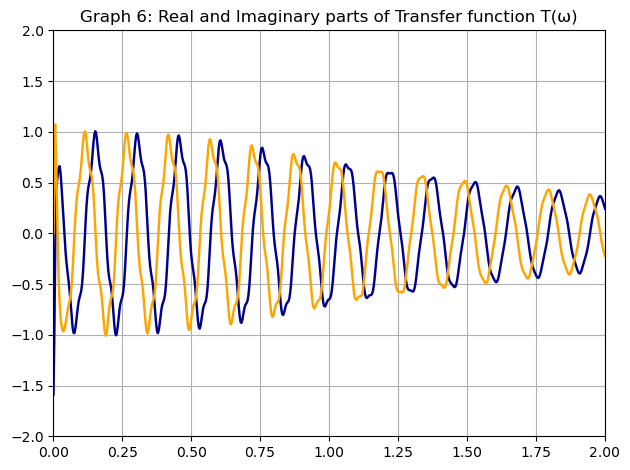

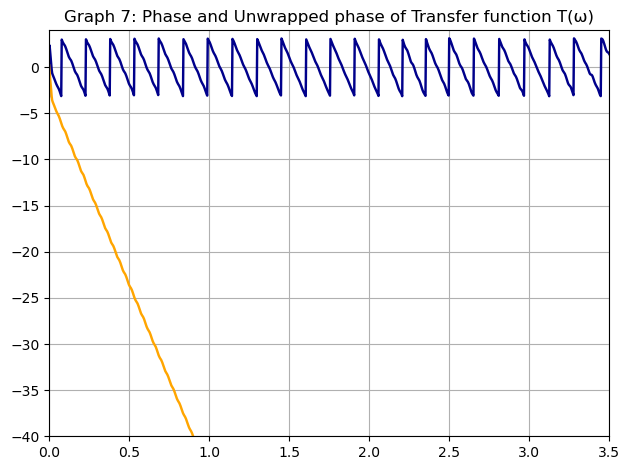

In [20]:
plt.plot( freq *1e-12 , tamp.real, linewidth=1.75, color='darkblue')
plt.plot( freq *1e-12 , tamp.imag, linewidth=1.75, color='orange')
plt.title("Graph 6: Real and Imaginary parts of Transfer function T(ω)", fontsize = 12)
plt.xlim(0,2)
plt.ylim(-2,2)
plt.grid()
plt.tight_layout()
plt.show()


plt.plot( freq *1e-12 , tphase, linewidth=1.75, color='darkblue')
plt.plot(freq *1e-12, tphase_unwrapped, linewidth=1.75, color='orange')
plt.title("Graph 7: Phase and Unwrapped phase of Transfer function T(ω)", fontsize = 12)
plt.xlim(0,3.5)
plt.ylim(-40,4)
plt.grid()
plt.tight_layout()
plt.show()

The next goal is to go back in time domain. We make an inverse Fourier transform on the sample signal. Then the difference __'amp_diff'__ is essentialy the difference between the sample and the inverse FFT of. We can later observe in the plots that is does re-create the ___ss___.   

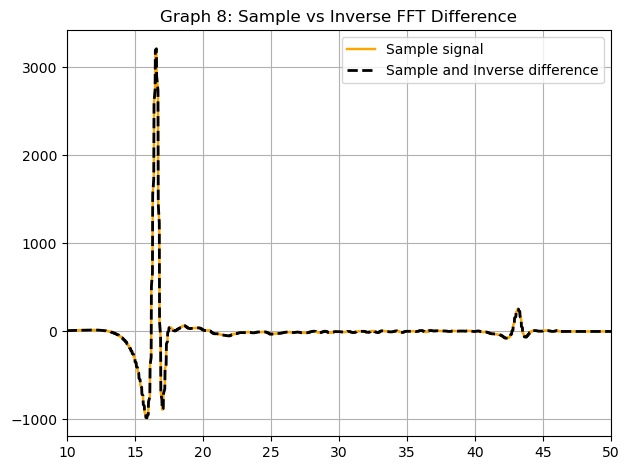

In [21]:

inv_fft = np.fft.ifft(ss, 23856)


amp_diff = ss - np.abs(inv_fft)

plt.title("Graph 8: Sample vs Inverse FFT Difference", fontsize = 12)
plt.plot(t *1e12, ss, color = "orange",  linewidth = 1.75, alpha = 1, label = "Sample signal")
plt.plot(t *1e12, amp_diff, color = "black",  linewidth = 2, linestyle = "dashed", alpha =1, label = "Sample and Inverse difference")
plt.xlim(10,50)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()